# 02 — U-Net segmentation → PyRadiomics features → versioned JSON records

**Objective.** Run the existing YOLO26n → U-Net pipeline with the trained checkpoints, map every
lesion mask back to the **original-resolution** image, validate it, extract PyRadiomics features, and
save one schema-validated JSON record per lesion and mask variant.

| variant | box | mask | represents |
|---|---|---|---|
| `gt_mask` | ground-truth box | ground-truth annotation | oracle / training features |
| `unet_on_gt_box` | ground-truth box | **U-Net prediction** | segmentation error only |
| `cascade` | **YOLO26n top box** | **U-Net prediction** | real inference, exactly as the app runs it |

Ground-truth masks are **never** substituted for predicted masks: each record's
`segmentation.mask_source` says which one it is, and notebook 04 evaluates real inference on
`cascade` records only.

**Prerequisites.** Notebook 01; checkpoints in `checkpoints/{yolo,unet,resnet}`; `requirements-research.txt`.

**Outputs.** `results/radiomics/records/*.json`, `results/radiomics/manifest.json`,
`results/radiomics/segmentation_feature_agreement.csv`, `results/radiomics/example_overlay.png`.

## Setup

In [1]:
import json
import os
import sys
from pathlib import Path

# Resolve the repo root whether the kernel starts in notebooks/ or at the root:
# config.yaml paths (dataset/, checkpoints/, results/) are relative to it.
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "config.yaml").exists() and (p / "bus_research").is_dir())
os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from utils.config import load_config
from utils.seed import get_device, set_seed

config = load_config(str(REPO_ROOT / "config.yaml"))
set_seed(config["seed"], config["deterministic"])
RESEARCH = config["research"]
print(f"Repo root: {REPO_ROOT}")

Repo root: /Users/mulatyazewchekol/Documents/My_Projects/Healthcare_Projects/Breast_Cancer_Detection


In [2]:
import bus_research

missing = bus_research.missing_dependencies()
print("Missing research dependencies:", missing or "none")
# If anything is missing, install the pinned optional set (see the comments in that file):
# %pip install -r requirements-research.txt

Missing research dependencies: none


In [3]:
import hashlib
import shutil
import time
from datetime import datetime, timezone

import cv2
import numpy as np
import pandas as pd
import torch

from bus_research import birads
from bus_research.feature_store import build_record, pseudonymize, save_record, write_manifest
from bus_research.radiomics_extract import (
    UNET_ACTIVATION, UNET_THRESHOLD, RadiomicsSettings, extract_radiomics_features, native_mask_from_roi)
from dataset.manifest import file_hash
from inference.pipeline import CADPipeline
from preprocessing.mask_to_yolo import component_mask
from preprocessing.normalization import load_image_rgb
from preprocessing.roi_utils import apply_mask, crop_roi

settings = RadiomicsSettings.from_config(config)
print(settings)
print("settings hash:", settings.settings_hash())

RadiomicsSettings(bin_width=8, feature_classes=('shape2D', 'firstorder', 'glcm', 'glrlm', 'glszm', 'gldm', 'ngtdm'), image_types=('Original',), normalize=False, resampled_pixel_spacing=None, interpolator='sitkBSpline', label=1, keep_largest_component=True, min_area_px=50, max_area_fraction=0.6, min_largest_component_fraction=0.9)
settings hash: b003a896becb517e


## 1. Load the trained pipeline (checkpoints are required here)

In [4]:
inf = config["inference"]
for key in ("yolo_weights", "unet_weights", "resnet_weights"):
    if not Path(inf[key]).exists():
        raise FileNotFoundError(f"{key} not found at {inf[key]}: train or copy the checkpoint first")

def checkpoint_version(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return f"sha256:{h.hexdigest()[:12]}"

CKPT = {k: checkpoint_version(inf[k]) for k in ("yolo_weights", "unet_weights", "resnet_weights")}
device = get_device(config.get("device"))
pipeline = CADPipeline(config, device=device)
print("device:", device)
print("checkpoints:", CKPT)
print("U-Net output -> mask:", UNET_ACTIVATION, ">", UNET_THRESHOLD, "(mirrors CADPipeline.segment)")

device: mps
checkpoints: {'yolo_weights': 'sha256:87d59200f450', 'unet_weights': 'sha256:160149a442cd', 'resnet_weights': 'sha256:3725d52a65c6'}
U-Net output -> mask: sigmoid > 0.5 (mirrors CADPipeline.segment)


## 2. One lesion, step by step (alignment check)

The U-Net sees a 256×256 resize of the padded box. Before extraction its mask is pasted back
into the original image through that same box, so shape and texture are measured at native
geometry with native intensities.

image (609, 501, 3), ROI box (120, 76, 483, 313), U-Net ROI mask (256, 256) -> native (609, 501)
Dice(U-Net native, ground truth) = 0.976


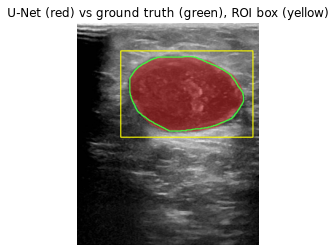

status: ok | QC: pass []
features per family: {'shape2D': 9, 'firstorder': 18, 'glcm': 24, 'glrlm': 16, 'glszm': 16, 'gldm': 14, 'ngtdm': 5}
invalid/unsupported: none
shape2D (pixel units): {'Elongation': 0.669, 'MajorAxisLength': 312.606, 'MaximumDiameter': 316.002, 'MeshSurface': 51199.5, 'MinorAxisLength': 209.16, 'Perimeter': 918.884, 'PerimeterSurfaceRatio': 0.018, 'PixelSurface': 51200.0, 'Sphericity': 0.873}


In [5]:
import matplotlib.pyplot as plt

lesions = {s: json.loads((Path(config["paths"]["splits_dir"]) / f"{s}_lesions.json").read_text())
           for s in ("train", "val", "test")}
row = lesions["test"][0]
image = load_image_rgb(row["image_path"])
gt_native = component_mask(row["source_mask_path"], row["component_label"]).astype(np.uint8)
roi, padded = crop_roi(image, tuple(row["bbox"]), pad_ratio=0.0, target_size=pipeline.roi_size)
unet_roi = pipeline.segment(roi)
unet_native = native_mask_from_roi(unet_roi, padded, image.shape)
dice = 2 * (gt_native & unet_native).sum() / (gt_native.sum() + unet_native.sum())
print(f"image {image.shape}, ROI box {padded}, U-Net ROI mask {unet_roi.shape} -> native {unet_native.shape}")
print(f"Dice(U-Net native, ground truth) = {dice:.3f}")

overlay = image.copy()
overlay[unet_native > 0] = (0.55 * overlay[unet_native > 0] + 0.45 * np.array([255, 60, 60])).astype(np.uint8)
contours, _ = cv2.findContours(gt_native, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
cv2.drawContours(overlay, contours, -1, (60, 255, 60), 2)
cv2.rectangle(overlay, padded[:2], padded[2:], (255, 255, 0), 2)
fig, ax = plt.subplots(figsize=(5, 4), dpi=72)
ax.imshow(overlay); ax.set_title("U-Net (red) vs ground truth (green), ROI box (yellow)"); ax.axis("off")
out_dir = REPO_ROOT / RESEARCH["radiomics"]["output_dir"]
out_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(out_dir / "example_overlay.png", bbox_inches="tight")
plt.show()

demo = extract_radiomics_features(image, unet_native, {"roi_bbox": list(padded)}, settings)
print("status:", demo["status"], "| QC:", demo["qc"]["status"], demo["qc"]["issues"])
print("features per family:", {k: len(v) for k, v in demo["features"].items()})
print("invalid/unsupported:", demo["feature_status"] or "none")
print("shape2D (pixel units):", {k: round(v, 3) for k, v in demo["features"]["shape2D"].items()})

## 3. Batch extraction over every split

Smoke-test first (`SMOKE_TEST = True` runs 5 lesions per split into a scratch directory), then
the full run. Each record carries the ResNet50 output computed on the same mask (uncalibrated), so
notebook 04 can compare models on identical cases without re-running the CNN.

In [6]:
SMOKE_TEST = False   # True: 5 lesions/split into results/radiomics_smoke/, for a quick check

LABEL_SOURCE = "BUSI class folder (benign/malignant as published by the dataset authors)"
RESNET_ID = f"resnet50@{CKPT['resnet_weights']}"
split_rows = {s: json.loads((Path(config["paths"]["splits_dir"]) / f"{s}.json").read_text())
              for s in ("train", "val", "test")}
target = REPO_ROOT / ("results/radiomics_smoke" if SMOKE_TEST else RESEARCH["radiomics"]["output_dir"])
if (target / "records").exists():
    shutil.rmtree(target / "records")   # deterministic ids: regenerate everything from scratch
group_of = {}                           # raw image id -> content-group pseudonym

def resnet_prediction(roi, roi_mask):
    _, _, probs = pipeline.classify(apply_mask(roi, roi_mask))
    return {"model_id": RESNET_ID, "prediction_type": "benign_vs_malignant",
            "class_probabilities": probs, "calibration_status": "uncalibrated"}

def save(image, mask_native, *, raw_id, lesion_key, variant, split, label, seg, prediction, entries):
    result = extract_radiomics_features(image, mask_native, {"roi_bbox": seg.get("roi_bbox_xyxy")}, settings)
    rec = build_record(
        image_key=raw_id, lesion_key=lesion_key, image=image, radiomics_result=result,
        segmentation=seg, descriptors=birads.empty_descriptors(),
        reference_labels={"benign_malignant": label, "birads_category": None, "label_source": LABEL_SOURCE,
                          "split": split},
        prediction=prediction,
        limitations=["Shape features in pixel units (no physical calibration)."],
        provenance={"variant": variant, "device": str(device), "checkpoints": CKPT, "pipeline": "notebook 02"},
    )
    path = save_record(target, rec)
    entries.append({"record_id": rec["record_id"], "image_id": rec["image_id"], "lesion_id": rec["lesion_id"],
                    "group_id": group_of[raw_id], "split": split, "variant": variant,
                    "record_path": str(path.relative_to(target)), "radiomics_status": rec["radiomics"]["status"],
                    "qc_status": rec["segmentation"]["quality_status"]})
    return rec

entries, detection_failures, dice_rows = [], [], []
t0 = time.time()
for split in ("train", "val", "test"):
    for r in split_rows[split]:
        group_of[r["image_id"]] = pseudonymize(file_hash(r["image_path"]), "grp")
    lesion_rows = lesions[split][:5] if SMOKE_TEST else lesions[split]
    for row in lesion_rows:
        image = load_image_rgb(row["image_path"])
        lesion_key = f"{Path(row['source_mask_path']).name}#{row['component_label']}"
        gt_native = component_mask(row["source_mask_path"], row["component_label"]).astype(np.uint8)
        roi, padded = crop_roi(image, tuple(row["bbox"]), pad_ratio=0.0, target_size=pipeline.roi_size)
        gt_roi = cv2.resize(gt_native[padded[1]:padded[3], padded[0]:padded[2]], pipeline.roi_size,
                            interpolation=cv2.INTER_NEAREST)
        save(image, gt_native, raw_id=row["image_id"], lesion_key=lesion_key, variant="gt_mask", split=split,
             label=row["label"], entries=entries, prediction=resnet_prediction(roi, gt_roi),
             seg={"model": "ground_truth_annotation", "checkpoint_version": None, "mask_source": "ground_truth",
                  "activation": None, "threshold": None, "bbox_source": "ground_truth",
                  "detection_confidence": None, "roi_bbox_xyxy": list(padded)})
        unet_roi = pipeline.segment(roi)
        unet_native = native_mask_from_roi(unet_roi, padded, image.shape)
        save(image, unet_native, raw_id=row["image_id"], lesion_key=lesion_key, variant="unet_on_gt_box",
             split=split, label=row["label"], entries=entries, prediction=resnet_prediction(roi, unet_roi),
             seg={"model": "unet", "checkpoint_version": CKPT["unet_weights"], "mask_source": "predicted",
                  "activation": UNET_ACTIVATION, "threshold": UNET_THRESHOLD, "bbox_source": "ground_truth",
                  "detection_confidence": None, "roi_bbox_xyxy": list(padded)})
        inter = int((gt_native & unet_native).sum())
        dice_rows.append({"split": split, "lesion": entries[-1]["lesion_id"],
                          "dice": 2 * inter / max(1, gt_native.sum() + unet_native.sum())})
    image_rows = split_rows[split][:5] if SMOKE_TEST else split_rows[split]
    for r in image_rows:
        try:
            case = pipeline.run(r["image_path"])
        except RuntimeError:
            detection_failures.append({"image_id": pseudonymize(r["image_id"], "img"), "split": split})
            continue
        native = native_mask_from_roi(case.mask, case.bbox, case.image.shape)
        save(case.image, native, raw_id=r["image_id"], lesion_key="top_detection", variant="cascade", split=split,
             label=r["label"], entries=entries,
             prediction={"model_id": RESNET_ID, "prediction_type": "benign_vs_malignant",
                         "class_probabilities": case.class_probs, "calibration_status": "uncalibrated"},
             seg={"model": "unet", "checkpoint_version": CKPT["unet_weights"], "mask_source": "predicted",
                  "activation": UNET_ACTIVATION, "threshold": UNET_THRESHOLD, "bbox_source": "yolo",
                  "detection_confidence": case.detection_confidence, "roi_bbox_xyxy": list(case.bbox)})
    print(f"{split}: done ({time.time() - t0:.0f}s elapsed, {len(entries)} records)")

manifest_path = write_manifest(target, entries, extra={
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "settings_hash": settings.settings_hash(),
    "radiomics_settings": settings.pyradiomics_settings(),
    "checkpoints": CKPT,
    "device": str(device),
    "detection_failures": detection_failures,
    "variants": {"gt_mask": "ground-truth box + annotation", "unet_on_gt_box": "ground-truth box + U-Net mask",
                 "cascade": "YOLO26n top box + U-Net mask (real inference)"},
})
print("manifest:", manifest_path.relative_to(REPO_ROOT))

train: done (114s elapsed, 1371 records)


val: done (139s elapsed, 1663 records)


test: done (164s elapsed, 1951 records)
manifest: results/radiomics/manifest.json


## 4. Extraction and QC summary

In [7]:
man = pd.DataFrame(entries)
print(pd.crosstab([man.variant, man.split], man.radiomics_status))
print()
print(pd.crosstab(man.variant, man.qc_status))
print("\ndetection failures (cascade, no YOLO box):", pd.Series([d["split"] for d in detection_failures]).value_counts().to_dict())

issue_counts = {}
for e in entries:
    rec = json.loads((target / e["record_path"]).read_text())
    for issue in rec["segmentation"]["quality_issues"]:
        issue_counts[(e["variant"], issue["code"])] = issue_counts.get((e["variant"], issue["code"]), 0) + 1
    for name, status in rec["radiomics"]["feature_status"].items():
        issue_counts[(e["variant"], f"feature:{name}:{status}")] = issue_counts.get((e["variant"], f"feature:{name}:{status}"), 0) + 1
print(pd.Series(issue_counts, name="count").sort_index().to_string() if issue_counts else "no QC issues")

radiomics_status       ok
variant        split     
cascade        test    88
               train  449
               val     84
gt_mask        test   100
               train  461
               val    104
unet_on_gt_box test   100
               train  461
               val    104

qc_status       pass  warn
variant                   
cascade          530    91
gt_mask          653    12
unet_on_gt_box   620    45

detection failures (cascade, no YOLO box): {'val': 14, 'test': 9, 'train': 3}
cascade         fragmented_mask         87
                touches_image_border     5
gt_mask         touches_image_border    12
unet_on_gt_box  fragmented_mask         40
                touches_image_border     5


## 5. Predicted-mask vs ground-truth-mask features (validation + test lesions)

For every val/test lesion, compare features from the U-Net mask with features from the annotation
of the same lesion, both inside the same ground-truth box. Agreement per feature is reported as
ICC(3,1) (consistency) and Spearman ρ. Low-agreement features are the ones most affected by
segmentation error. Notebook 04 measures the downstream effect on classification.

In [8]:
from scipy.stats import spearmanr

from bus_research.radiomics_extract import flat_features

def load_variant(variant, splits=("val", "test")):
    out = {}
    for e in entries:
        if e["variant"] == variant and e["split"] in splits and e["radiomics_status"] == "ok":
            rec = json.loads((target / e["record_path"]).read_text())
            out[e["lesion_id"]] = flat_features(rec["radiomics"])
    return out

gt, pred = load_variant("gt_mask"), load_variant("unet_on_gt_box")
common = sorted(gt.keys() & pred.keys())
names = sorted(set.intersection(*(set(gt[k]) & set(pred[k]) for k in common))) if common else []

def icc31(a, b):
    x = np.stack([a, b], axis=1)
    n, k = x.shape
    grand = x.mean()
    msr = k * ((x.mean(1) - grand) ** 2).sum() / (n - 1)
    mse = ((x - x.mean(1, keepdims=True) - x.mean(0, keepdims=True) + grand) ** 2).sum() / ((n - 1) * (k - 1))
    return (msr - mse) / (msr + mse) if (msr + mse) > 0 else np.nan

rows = []
for name in names:
    a = np.array([gt[k][name] for k in common]); b = np.array([pred[k][name] for k in common])
    rows.append({"feature": name, "icc3_1": icc31(a, b), "spearman": spearmanr(a, b).statistic,
                 "median_abs_rel_diff": float(np.median(np.abs(b - a) / (np.abs(a) + 1e-9)))})
agreement = pd.DataFrame(rows).sort_values("icc3_1")
agreement.to_csv(target / "segmentation_feature_agreement.csv", index=False)
dice_df = pd.DataFrame(dice_rows)
print(f"lesions compared: {len(common)} | U-Net Dice on val+test: "
      f"median {dice_df[dice_df.split != 'train'].dice.median():.3f}, "
      f"mean {dice_df[dice_df.split != 'train'].dice.mean():.3f}")
print(f"features with ICC >= 0.90: {(agreement.icc3_1 >= 0.9).sum()}/{len(agreement)}; "
      f"ICC < 0.75: {(agreement.icc3_1 < 0.75).sum()}")
print("\nleast stable under segmentation error:")
print(agreement.head(10).round(3).to_string(index=False))
print("\nby family (median ICC):")
print(agreement.assign(family=agreement.feature.str.split(".").str[0]).groupby("family").icc3_1.median().round(3))

lesions compared: 204 | U-Net Dice on val+test: median 0.942, mean 0.935
features with ICC >= 0.90: 94/102; ICC < 0.75: 1

least stable under segmentation error:
                               feature  icc3_1  spearman  median_abs_rel_diff
                    shape2D.Sphericity   0.714     0.781                0.029
glrlm.GrayLevelNonUniformityNormalized   0.858     0.939                0.048
glszm.GrayLevelNonUniformityNormalized   0.858     0.939                0.048
                      firstorder.Range   0.873     0.897                0.016
                             glcm.Imc2   0.873     0.975                0.001
                    firstorder.Maximum   0.875     0.900                0.015
                        ngtdm.Contrast   0.887     0.942                0.098
                   firstorder.Kurtosis   0.896     0.923                0.099
                        ngtdm.Busyness   0.910     0.968                0.077
                        ngtdm.Strength   0.914     0.944  

## Limitations

* **Pixel units.** BUSI has no physical spacing, so area, perimeter and axis lengths are in pixels, and
  images are acquired at different zoom levels. Cross-image shape comparisons mix lesion size with
  acquisition scale.
* **Intensity.** B-mode gray levels depend on gain/TGC settings that BUSI does not record, so
  first-order features are not standardised across scanners.
* **Train-split predicted masks are in-sample.** The U-Net and YOLO were trained on the train split,
  so `unet_on_gt_box`/`cascade` records for *train* images are optimistic. Notebook 04 trains on
  `gt_mask` features and evaluates real inference on held-out `cascade` records only.
* **One lesion per image in the cascade.** The app (and `cascade` variant) analyses the top YOLO box.
  For the 17 multi-lesion images, other lesions are not analysed.
* **Not BI-RADS descriptors.** Radiomics values are quantitative descriptors. Every record keeps
  `birads_descriptors` as `not_assessed`/`unavailable`; nothing is inferred from them.